# Foundations of Data Manipulation and Data Analysis
## Global Missing Migrants Dataset

This notebook provides a practical introduction to data analysis using the **Global Missing Migrants Dataset**.

### Learning objectives
- Understand Python data structures and Pandas Series/DataFrames.
- Inspect and clean a real-world CSV dataset.
- Identify data types, missing values, duplicates, and data-quality issues.
- Apply descriptive statistics and grouped summaries.
- Explore patterns by region, route, cause, location, and date where those fields are available.
- Create appropriate visualizations and interpret results cautiously.
- Export cleaned data and summary tables.

**Important:** Records of missing migrants and deaths/disappearances are documented cases and may not represent the full scale of migration-related deaths or disappearances. Treat the data as incomplete and avoid interpreting missing records as evidence that an event did not occur.

Run the notebook from top to bottom.

## 1. Setup and imports

We use `pandas` for data manipulation, `numpy` for numerical operations, `matplotlib` and `seaborn` for visualizations, and `pathlib` for file paths.

In [57]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 40)

FILE_PATH = Path("Global Missing Migrants Dataset.csv")
if not FILE_PATH.exists():
    FILE_PATH = Path("/mnt/data/Global Missing Migrants Dataset.csv")

print("File exists:", FILE_PATH.exists())
print("File path:", FILE_PATH)

File exists: True
File path: Global Missing Migrants Dataset.csv


## 2. Load the CSV file

A CSV file is a plain-text table. `read_csv()` loads it into a Pandas DataFrame. We first inspect the dimensions and a few records.

In [58]:
df_raw = pd.read_csv(FILE_PATH, low_memory=False)

print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]:,}")
display(df_raw.head())

Rows: 13,020
Columns: 19


,Incident Type,Incident year,Reported Month,Region of Origin,Region of Incident,Country of Origin,Number of Dead,Minimum Estimated Number of Missing,Total Number of Dead and Missing,Number of Survivors,Number of Females,Number of Males,Number of Children,Cause of Death,Migration route,Location of death,Information Source,Coordinates,UNSD Geographical Grouping
0,Incident,2014,January,Central America,North America,Guatemala,1.0,0,1,0,0,1,0,Mixed or unknown,US-Mexico border crossing,Pima Country Office of the Medical Examiner ju...,Pima County Office of the Medical Examiner (PC...,"31.650259, -110.366453",Northern America
1,Incident,2014,January,Latin America / Caribbean (P),North America,Unknown,1.0,0,1,0,0,0,0,Mixed or unknown,US-Mexico border crossing,Pima Country Office of the Medical Examiner ju...,Pima County Office of the Medical Examiner (PC...,"31.59713, -111.73756",Northern America
2,Incident,2014,January,Latin America / Caribbean (P),North America,Unknown,1.0,0,1,0,0,0,0,Mixed or unknown,US-Mexico border crossing,Pima Country Office of the Medical Examiner ju...,Pima County Office of the Medical Examiner (PC...,"31.94026, -113.01125",Northern America
3,Incident,2014,January,Central America,North America,Mexico,1.0,0,1,0,0,1,0,Violence,US-Mexico border crossing,"near Douglas, Arizona, USA","Ministry of Foreign Affairs Mexico, Pima Count...","31.506777, -109.315632",Northern America
4,Incident,2014,January,Northern Africa,Europe,Sudan,1.0,0,1,2,0,1,0,Harsh environmental conditions / lack of adequ...,NaN,Border between Russia and Estonia,EUBusiness (Agence France-Presse),"59.1551, 28",Northern Europe


## 3. Foundational data structures

- **DataFrame:** a two-dimensional table.
- **Series:** one column from a DataFrame.
- **List:** an ordered collection such as the column names.
- **Dictionary:** key-value pairs useful for metadata and summaries.
- **Data types:** indicate whether a column contains text, numbers, dates, or Boolean values.

In [59]:
column_names = df_raw.columns.tolist()
dataset_metadata = {
    "dataset_name": "Global Missing Migrants Dataset",
    "rows": int(df_raw.shape[0]),
    "columns": int(df_raw.shape[1]),
    "column_names": column_names
}

print("DataFrame type:", type(df_raw))
print("Series type:", type(df_raw.iloc[:, 0]))
print("Column-name list type:", type(column_names))
print("Metadata dictionary type:", type(dataset_metadata))
print("\nColumn names:")
print(column_names)

DataFrame type: <class 'pandas.core.frame.DataFrame'>
Series type: <class 'pandas.core.series.Series'>
Column-name list type: <class 'list'>
Metadata dictionary type: <class 'dict'>

Column names:
['Incident Type', 'Incident year', 'Reported Month', 'Region of Origin', 'Region of Incident', 'Country of Origin', 'Number of Dead', 'Minimum Estimated Number of Missing', 'Total Number of Dead and Missing', 'Number of Survivors', 'Number of Females', 'Number of Males', 'Number of Children', 'Cause of Death', 'Migration route', 'Location of death', 'Information Source', 'Coordinates', 'UNSD Geographical Grouping']


## 4. Data dictionary and first inspection

This table summarizes column types, missing counts, and missing percentages. The dataset's exact column names may evolve between published versions, so later sections identify likely fields from their names.

In [60]:
data_dictionary = pd.DataFrame({
    "column": df_raw.columns.astype(str),
    "dtype": df_raw.dtypes.astype(str).values,
    "missing_count": df_raw.isna().sum().values,
    "missing_percent": (df_raw.isna().mean().values * 100).round(2),
    "unique_values": df_raw.nunique(dropna=True).values
}).sort_values("missing_percent", ascending=False)

display(data_dictionary)

,column,dtype,missing_count,missing_percent,unique_values
14,Migration route,object,3021,23.20,25
6,Number of Dead,float64,550,4.22,86
17,Coordinates,object,36,0.28,9582
3,Region of Origin,object,22,0.17,33
16,Information Source,object,8,0.06,3803
5,Country of Origin,object,8,0.06,335
18,UNSD Geographical Grouping,object,1,0.01,19
11,Number of Males,int64,0,0.00,59
15,Location of death,object,0,0.00,7460
13,Cause of Death,object,0,0.00,15


In [61]:
display(df_raw.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Incident Type,13020,4,Incident,12670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Incident year,13020.0,NaN,NaN,NaN,2019.060753,2.418738,2014.0,2017.0,2019.0,2021.0,2023.0
Reported Month,13020,12,June,1269,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region of Origin,12998,33,Latin America / Caribbean (P),2164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region of Incident,13020,16,North America,2706,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country of Origin,13012,335,Unknown,7220,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Number of Dead,12470.0,NaN,NaN,NaN,2.623737,9.728163,0.0,1.0,1.0,2.0,750.0
Minimum Estimated Number of Missing,13020.0,NaN,NaN,NaN,1.904378,15.645297,-2.0,0.0,0.0,0.0,750.0
Total Number of Dead and Missing,13020.0,NaN,NaN,NaN,4.417281,19.95063,1.0,1.0,1.0,2.0,1022.0
Number of Survivors,13020.0,NaN,NaN,NaN,6.553763,42.315444,-2.0,0.0,0.0,0.0,1950.0


In [62]:
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))

Exact duplicate rows: 641


## 5. Standardize column names

We create a working copy and standardize column names for easier coding. The original DataFrame `df_raw` remains unchanged.

In [63]:
df = df_raw.copy()
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^0-9a-zA-Z]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns.tolist())
display(df.head())

['incident_type', 'incident_year', 'reported_month', 'region_of_origin', 'region_of_incident', 'country_of_origin', 'number_of_dead', 'minimum_estimated_number_of_missing', 'total_number_of_dead_and_missing', 'number_of_survivors', 'number_of_females', 'number_of_males', 'number_of_children', 'cause_of_death', 'migration_route', 'location_of_death', 'information_source', 'coordinates', 'unsd_geographical_grouping']


,incident_type,incident_year,reported_month,region_of_origin,region_of_incident,country_of_origin,number_of_dead,minimum_estimated_number_of_missing,total_number_of_dead_and_missing,number_of_survivors,number_of_females,number_of_males,number_of_children,cause_of_death,migration_route,location_of_death,information_source,coordinates,unsd_geographical_grouping
0,Incident,2014,January,Central America,North America,Guatemala,1.0,0,1,0,0,1,0,Mixed or unknown,US-Mexico border crossing,Pima Country Office of the Medical Examiner ju...,Pima County Office of the Medical Examiner (PC...,"31.650259, -110.366453",Northern America
1,Incident,2014,January,Latin America / Caribbean (P),North America,Unknown,1.0,0,1,0,0,0,0,Mixed or unknown,US-Mexico border crossing,Pima Country Office of the Medical Examiner ju...,Pima County Office of the Medical Examiner (PC...,"31.59713, -111.73756",Northern America
2,Incident,2014,January,Latin America / Caribbean (P),North America,Unknown,1.0,0,1,0,0,0,0,Mixed or unknown,US-Mexico border crossing,Pima Country Office of the Medical Examiner ju...,Pima County Office of the Medical Examiner (PC...,"31.94026, -113.01125",Northern America
3,Incident,2014,January,Central America,North America,Mexico,1.0,0,1,0,0,1,0,Violence,US-Mexico border crossing,"near Douglas, Arizona, USA","Ministry of Foreign Affairs Mexico, Pima Count...","31.506777, -109.315632",Northern America
4,Incident,2014,January,Northern Africa,Europe,Sudan,1.0,0,1,2,0,1,0,Harsh environmental conditions / lack of adequ...,NaN,Border between Russia and Estonia,EUBusiness (Agence France-Presse),"59.1551, 28",Northern Europe


## 6. Data quality: missing values and duplicates

Missing data is common in incident-level humanitarian datasets. A blank value can mean that information was not available or not reported; it should not automatically be replaced with zero. We remove exact duplicate rows in a separate working dataset.

In [64]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing_summary)
df_clean = df.drop_duplicates().copy()

print(f"Rows before removing exact duplicates: {len(df):,}")
print(f"Rows after removing exact duplicates:  {len(df_clean):,}")
print(f"Duplicate rows removed:                {len(df) - len(df_clean):,}")

,missing_count,missing_percent
migration_route,3021,23.20
number_of_dead,550,4.22
coordinates,36,0.28
region_of_origin,22,0.17
information_source,8,0.06
country_of_origin,8,0.06
unsd_geographical_grouping,1,0.01
number_of_males,0,0.00
location_of_death,0,0.00
cause_of_death,0,0.00


Rows before removing exact duplicates: 13,020
Rows after removing exact duplicates:  12,379
Duplicate rows removed:                641


## 7. Identify date, numeric, and categorical columns

We attempt to identify likely date columns by their names and parse them to datetime. We also report numeric and categorical fields for later analysis.

In [65]:
date_candidates = [
    c for c in df_clean.columns
    if any(k in c.lower() for k in ["date", "incident", "reported", "incident_date"])
]

date_parse_report = []
for col in date_candidates:
    parsed = pd.to_datetime(df_clean[col], errors="coerce")
    nonmissing = df_clean[col].notna().sum()
    parse_rate = parsed.notna().sum() / nonmissing if nonmissing else 0
    date_parse_report.append({
        "column": col,
        "parse_rate_percent": round(parse_rate * 100, 2)
    })
    # Convert if most populated values parse as dates.
    if nonmissing and parse_rate >= 0.70:
        df_clean[col] = parsed

display(pd.DataFrame(date_parse_report, columns=["column", "parse_rate_percent"]))
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
date_cols = df_clean.select_dtypes(include=["datetime", "datetimetz"]).columns.tolist()
categorical_cols = df_clean.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Date columns:", date_cols)
print("Categorical columns:", categorical_cols)

,column,parse_rate_percent
0,incident_type,0.0
1,incident_year,100.0
2,reported_month,0.0
3,region_of_incident,0.0


Numeric columns: ['number_of_dead', 'minimum_estimated_number_of_missing', 'total_number_of_dead_and_missing', 'number_of_survivors', 'number_of_females', 'number_of_males', 'number_of_children']
Date columns: ['incident_year']
Categorical columns: ['incident_type', 'reported_month', 'region_of_origin', 'region_of_incident', 'country_of_origin', 'cause_of_death', 'migration_route', 'location_of_death', 'information_source', 'coordinates', 'unsd_geographical_grouping']


## 8. Explore category frequencies

Frequency tables help identify the most common values in fields such as region, route, cause, or location. The notebook uses the actual categorical columns available in the uploaded dataset.

In [66]:
for col in categorical_cols[:10]:
    print(f"\nTop values for: {col}")
    display(
        df_clean[col].astype("string")
        .fillna("(Missing)")
        .value_counts()
        .head(15)
        .rename_axis(col)
        .reset_index(name="record_count")
    )


Top values for: incident_type


,incident_type,record_count
0,Incident,12029
1,Split Incident,261
2,Cumulative Incident,84
3,"Incident,Split Incident",5



Top values for: reported_month


,reported_month,record_count
0,June,1235
1,September,1155
2,July,1146
3,October,1141
4,August,1105
5,November,993
6,May,978
7,January,973
8,December,967
9,April,930



Top values for: region_of_origin


...

,location_of_death,record_count
0,Pima Country Office of the Medical Examiner ju...,1036
1,Pima County Office of the Medical Examiner jur...,403
2,"Agadez, Niger",112
3,"Sahara desert, Libya",112
4,"Sabha, Libya",97
5,"Unspecified location in the Sahara desert, Libya",71
6,"Unspecified location in the Sahara Desert, Libya",58
7,"Bani Walid, Libya",57
8,"Bamako, Mali",54
9,"Unspecified location, Libya",52



Top values for: information_source


,information_source,record_count
0,Pima County Office of the Medical Examiner (PC...,1452
1,IOM Afghanistan,1099
2,Mixed Migration Monitoring Mechanism Initiativ...,1034
3,Mixed Migration Monitoring Mechanism Initative...,962
4,Mixed Migration Monitoring Mechanism Initiativ...,649
5,IOM Libya,347
6,MHub,172
7,US Border Patrol,132
8,Syrian Observatory for Human Rights,97
9,Zócalo,96



Top values for: coordinates


,coordinates,record_count
0,"35.68940913, 51.38958967",31
1,"35.72628222, 51.37384373",30
2,"33.01479981, 12.54897854",30
3,"29.63186286, 52.51236196",28
4,"34.2533716, 14.4988153",26
5,"17.25620749, 43.20231",25
6,"19.635357, 27.103538",25
7,"27.02249, 14.44099",25
8,"15.5015341, 32.5025561",24
9,"23.2488413, 19.7242161",24


## 9. Descriptive statistics

For numeric variables, calculate count, mean, standard deviation, minimum, quartiles, and maximum. Interpret these summaries according to each variable's meaning and units.

In [67]:
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
if numeric_cols:
    display(df_clean[numeric_cols].describe().T)
else:
    print("No numeric columns were detected. Inspect the data dictionary and convert numeric-looking fields where appropriate.")

,count,mean,std,min,25%,50%,75%,max
number_of_dead,11845.0,2.697847,9.968320,0.0,1.0,1.0,2.0,750.0
minimum_estimated_number_of_missing,12379.0,2.000242,16.039092,-2.0,0.0,0.0,0.0,750.0
total_number_of_dead_and_missing,12379.0,4.581711,20.443476,1.0,1.0,1.0,2.0,1022.0
number_of_survivors,12379.0,6.893206,43.370300,-2.0,0.0,0.0,0.0,1950.0
number_of_females,12379.0,0.478310,2.924550,0.0,0.0,0.0,0.0,94.0
number_of_males,12379.0,1.128686,3.906836,0.0,0.0,1.0,1.0,135.0
number_of_children,12379.0,0.248728,2.478167,0.0,0.0,0.0,0.0,250.0


## 10. Detect likely analytical dimensions

Column names can differ across dataset releases. This helper identifies likely date, region, route, cause, country, location, and fatality-related fields. Check the suggestions before using them in a report.

In [68]:
def find_columns(keywords, columns):
    return [c for c in columns if any(keyword in c.lower() for keyword in keywords)]

all_cols = df_clean.columns.tolist()
candidates = {
    "date": find_columns(["date", "incident", "reported"], all_cols),
    "region": find_columns(["region", "subregion"], all_cols),
    "route": find_columns(["route", "migration"], all_cols),
    "cause": find_columns(["cause", "incident_type", "incident"], all_cols),
    "country": find_columns(["country", "origin", "destination"], all_cols),
    "location": find_columns(["location", "coordinates", "latitude", "longitude", "lat", "lon"], all_cols),
    "dead_missing_count": find_columns(["dead", "missing", "number_dead", "number_missing", "total_dead"], all_cols)
}
for key, value in candidates.items():
    print(f"{key}: {value}")

# Review these selections and adjust manually if needed.
DATE_COL = next((c for c in candidates["date"] if c in date_cols), None)
REGION_COL = candidates["region"][0] if candidates["region"] else None
ROUTE_COL = candidates["route"][0] if candidates["route"] else None
CAUSE_COL = candidates["cause"][0] if candidates["cause"] else None
COUNTRY_COL = candidates["country"][0] if candidates["country"] else None

print("\nSelected fields:", {
    "date": DATE_COL, "region": REGION_COL, "route": ROUTE_COL,
    "cause": CAUSE_COL, "country": COUNTRY_COL
})

date: ['incident_type', 'incident_year', 'reported_month', 'region_of_incident']
region: ['region_of_origin', 'region_of_incident']
route: ['migration_route']
cause: ['incident_type', 'incident_year', 'region_of_incident', 'cause_of_death']
country: ['region_of_origin', 'country_of_origin']
location: ['location_of_death', 'coordinates']
dead_missing_count: ['number_of_dead', 'minimum_estimated_number_of_missing', 'total_number_of_dead_and_missing']

Selected fields: {'date': 'incident_year', 'region': 'region_of_origin', 'route': 'migration_route', 'cause': 'incident_type', 'country': 'region_of_origin'}


## 11. Visualize categorical patterns

Bar charts are useful for comparing counts across categories. Here we plot the most frequently recorded categories in selected dimensions when those fields are present.

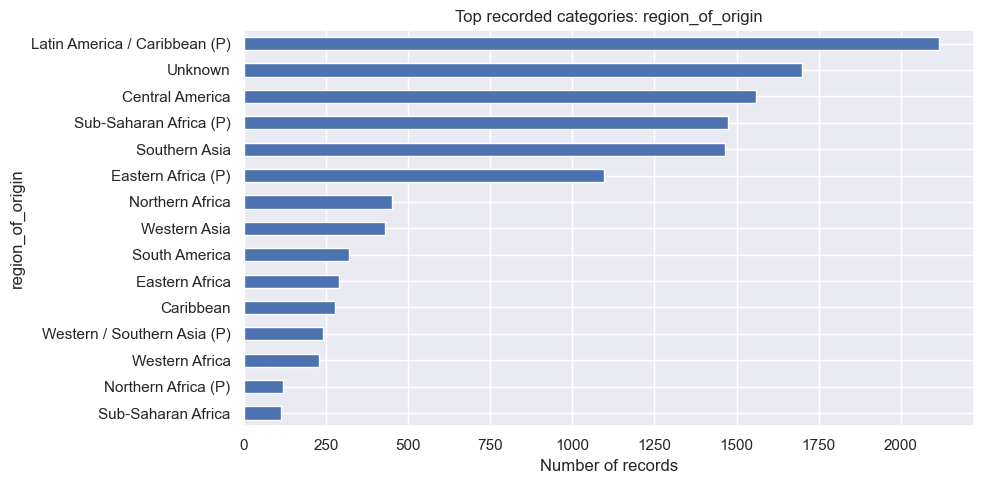

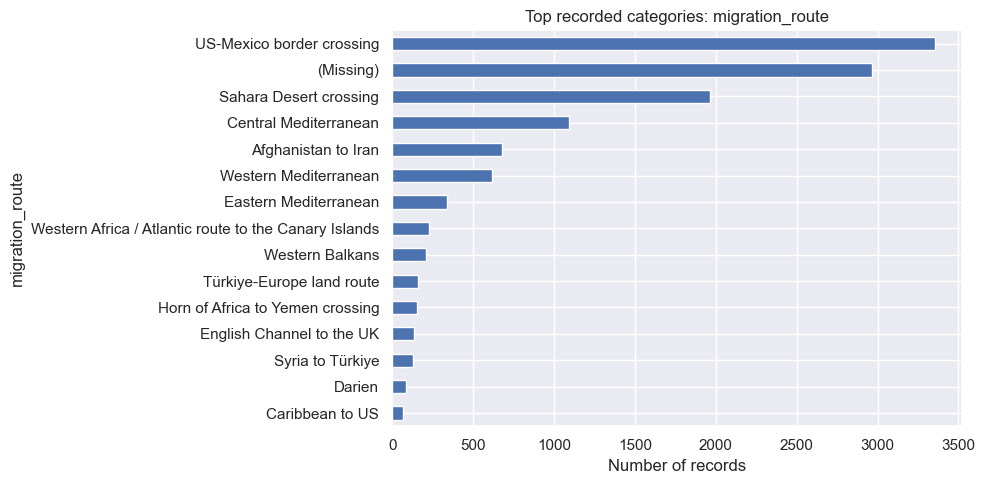

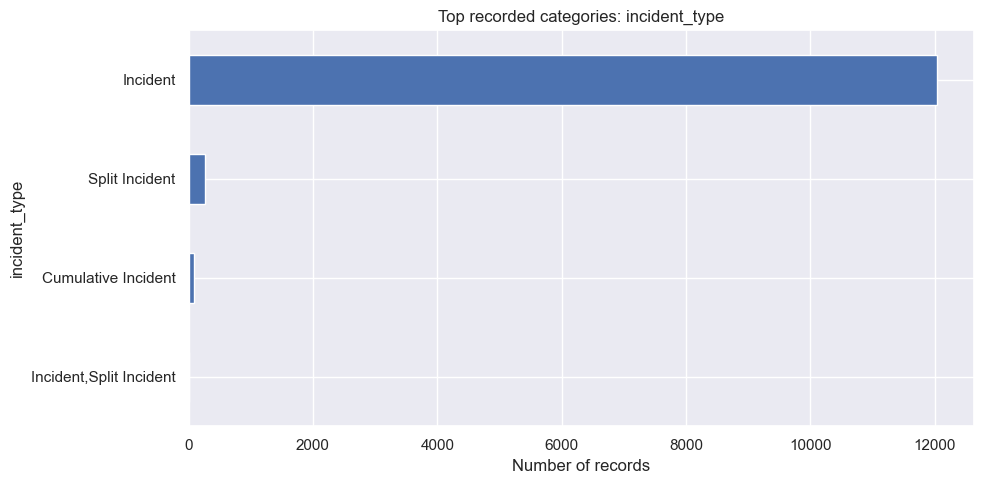

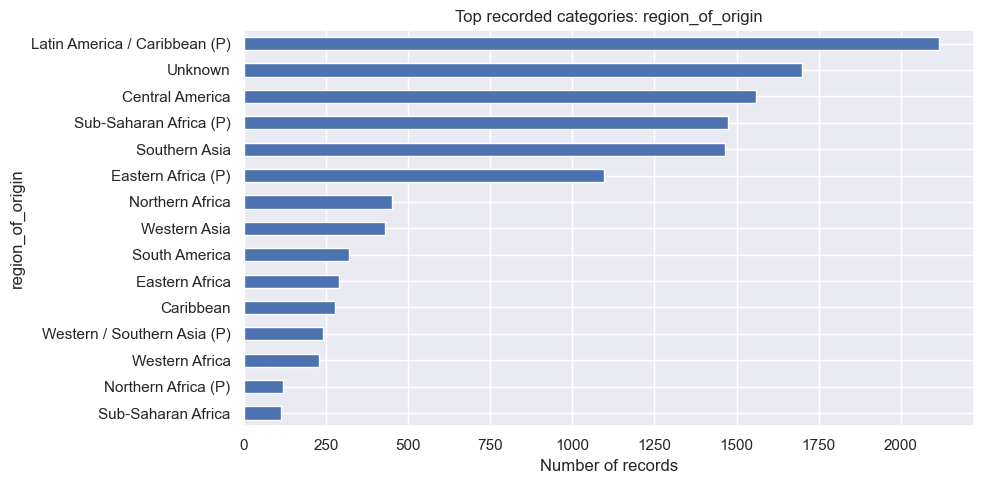

In [69]:
plot_columns = [c for c in [REGION_COL, ROUTE_COL, CAUSE_COL, COUNTRY_COL] if c]
for col in plot_columns[:4]:
    counts = (
        df_clean[col].astype("string").fillna("(Missing)")
        .value_counts().head(15).sort_values()
    )
    counts.plot(kind="barh")
    plt.title(f"Top recorded categories: {col}")
    plt.xlabel("Number of records")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## 12. Date-based analysis and trends

If a date column was detected, derive year and month fields and examine the number of recorded incidents over time. This is a count of records in the dataset, not necessarily a complete count of all real-world incidents.

,record_count
year,
1970,12379


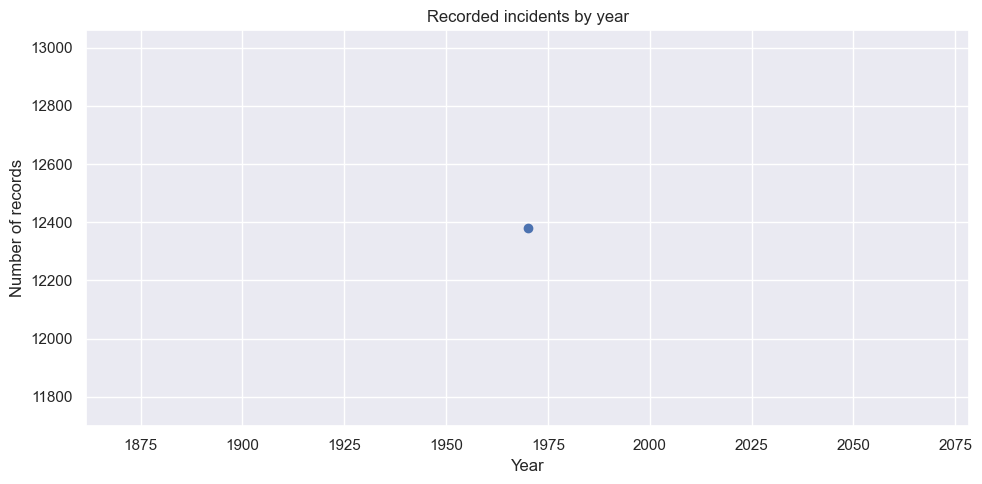

In [70]:
if DATE_COL:
    df_clean["analysis_date"] = pd.to_datetime(df_clean[DATE_COL], errors="coerce")
    dated = df_clean.dropna(subset=["analysis_date"]).copy()
    if not dated.empty:
        dated["year"] = dated["analysis_date"].dt.year
        dated["month"] = dated["analysis_date"].dt.to_period("M").astype(str)

        annual_records = dated.groupby("year").size().rename("record_count")
        display(annual_records.to_frame())

        annual_records.plot(marker="o")
        plt.title("Recorded incidents by year")
        plt.xlabel("Year")
        plt.ylabel("Number of records")
        plt.tight_layout()
        plt.show()

        monthly_records = dated.groupby("month").size().rename("record_count")
        if len(monthly_records) > 1:
            monthly_records.tail(60).plot()
            plt.title("Monthly records (most recent 60 months in the data)")
            plt.xlabel("Month")
            plt.ylabel("Number of records")
            plt.xticks(rotation=45, ha="right")
            plt.tight_layout()
            plt.show()
    else:
        print("Date column was detected but no values could be parsed.")
else:
    print("No suitable date column was detected. Set DATE_COL manually if a date field exists.")

## 13. Numeric distributions and outliers

Histograms show the distribution of numeric variables. Box plots help reveal extreme values, which should be investigated rather than removed automatically. Incident counts may be highly skewed.

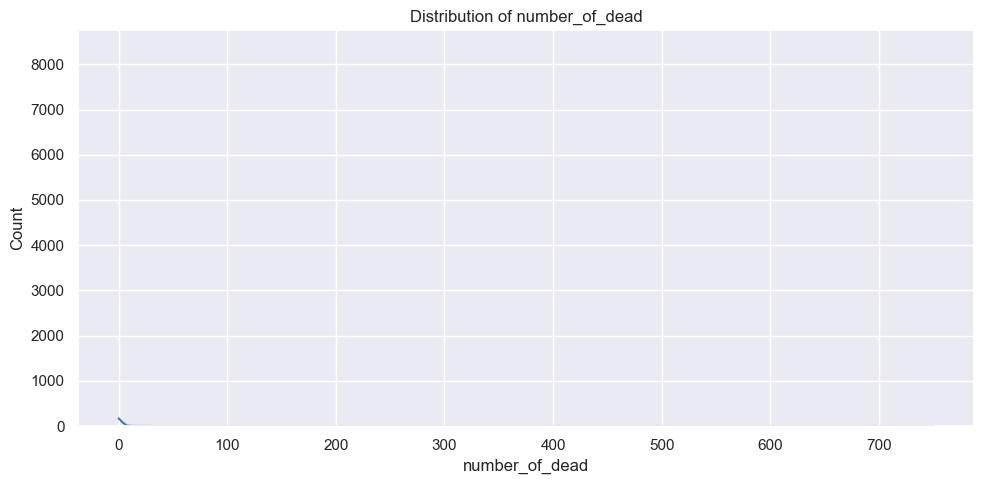

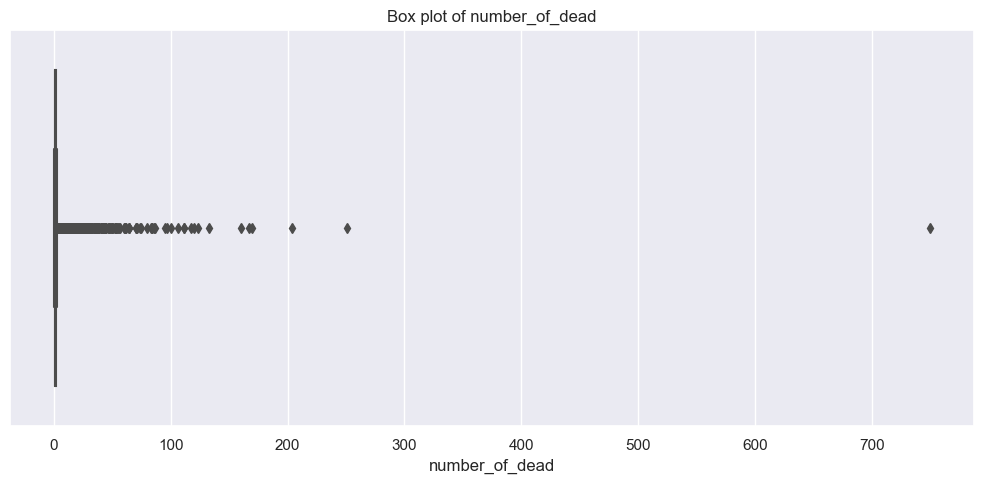

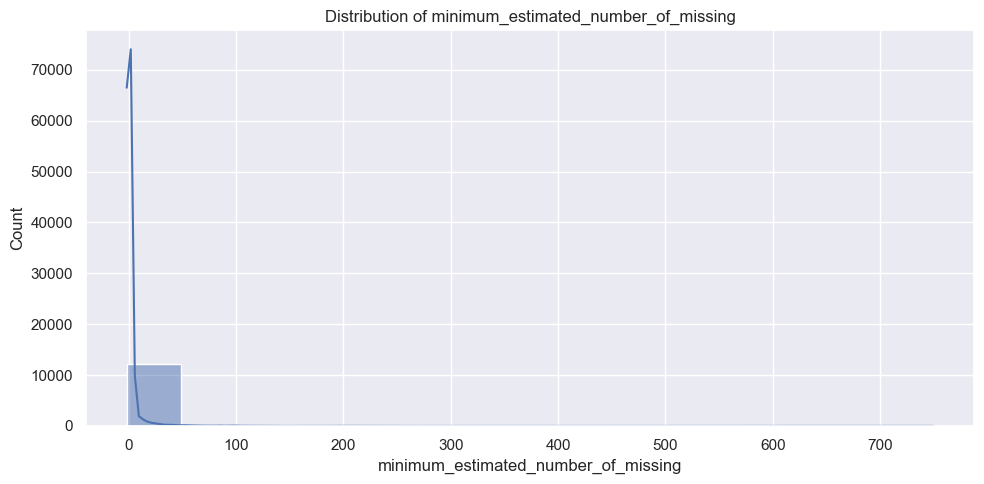

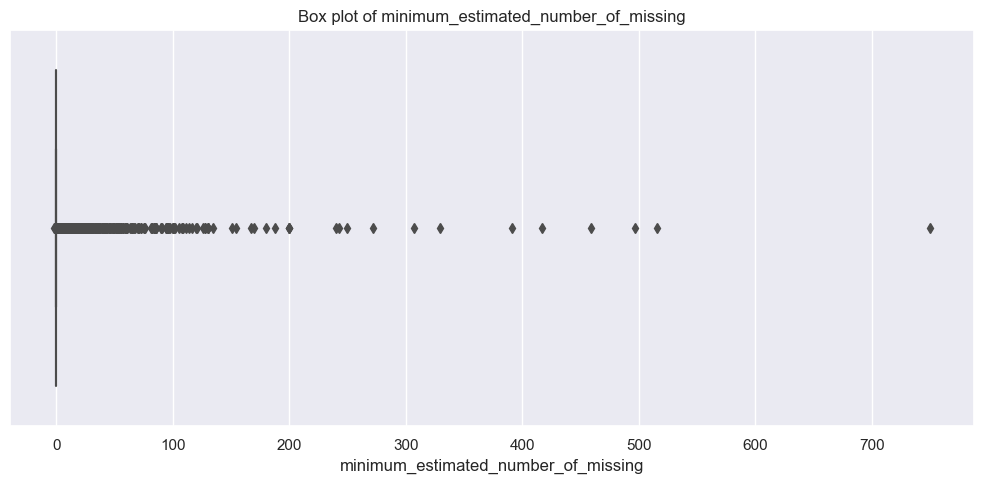

In [ ]:
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()

for col in numeric_cols[:4]:
    values = df_clean[col].dropna()
    if values.empty:
        continue
    sns.histplot(values, kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

    sns.boxplot(x=values)
    plt.title(f"Box plot of {col}")
    plt.tight_layout()
    plt.show()

## 14. Correlation analysis

Correlation summarizes linear association between numeric variables. It does not establish causation. Avoid treating unrelated counts or identifiers as meaningful correlated measures.

In [ ]:
# 1. Select numeric columns
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
if len(numeric_cols) >= 2:
    # 2. Remove columns with no variation
    variable_cols = [col for col in numeric_cols if df_clean[col].nunique(dropna=True) > 1]
    if len(variable_cols) >= 2:
        # 3. Calculate correlation matrix
        corr = df_clean[variable_cols].corr(method="pearson")
        # 4. Display correlation matrix
        display(corr.round(2))
        # 5. Select up to 15 variables for the heatmap
        corr_view = corr.iloc[:15, :15]
        # 6. Plot heatmap
        plt.figure(figsize=(14, 10))
        sns.heatmap(corr_view, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", linewidths=0.5, cbar_kws={
            "label": "Pearson Correlation Coefficient"})
        plt.title("Correlation Heatmap of Numeric Variables", fontsize=15, fontweight="bold")
        plt.xticks(rotation=45, ha="right")
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.show()
        # 7. Identify the strongest correlations
        upper_triangle = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        strong_corr = (upper_triangle.stack().rename("Correlation").reset_index())
        strong_corr.columns = ["Variable 1", "Variable 2", "Correlation"]
        strong_corr["Absolute Correlation"] = (strong_corr["Correlation"].abs())
        strong_corr = strong_corr.sort_values("Absolute Correlation", ascending=False)
        print("Top 10 strongest correlations:")
        display(strong_corr.head(10).round(3))
    else:
        print("At least two numeric columns with variation are required.")
else:
    print("At least two numeric variables are needed.")

## 15. Statistical methods: mean, median, spread, and percentiles

These measures describe the distribution of a numeric variable. In a dataset of migration incidents, the appropriate measure depends on what the variable represents. For example, incident-level counts may be skewed, making the median useful alongside the mean.

In [ ]:
def descriptive_summary(data, column):
    values = pd.to_numeric(data[column], errors="coerce").dropna()
    return {
        "variable": column,
        "n": int(values.size),
        "mean": values.mean(),
        "median": values.median(),
        "standard_deviation": values.std(),
        "variance": values.var(),
        "minimum": values.min(),
        "25th_percentile": values.quantile(0.25),
        "75th_percentile": values.quantile(0.75),
        "maximum": values.max()
    }

if numeric_cols:
    display(pd.DataFrame([descriptive_summary(df_clean, c) for c in numeric_cols[:10]]))
else:
    print("No numeric columns are available for descriptive statistics.")

## 16. Grouped summaries

Use `groupby()` to compare record counts and numeric summaries by region, route, cause, or country. Always verify the meaning of each field and whether missing categories should be included.

In [ ]:
for group_col in [REGION_COL, ROUTE_COL, CAUSE_COL, COUNTRY_COL]:
    if group_col:
        print(f"\nRecord counts by {group_col}")
        display(
            df_clean.groupby(group_col, dropna=False)
            .size().sort_values(ascending=False)
            .head(20).rename("record_count").to_frame()
        )

if REGION_COL and numeric_cols:
    value_cols = numeric_cols[:5]
    print(f"\nNumeric summaries by {REGION_COL}")
    display(df_clean.groupby(REGION_COL, dropna=False)[value_cols].agg(["count", "mean", "median", "max"]).head(20))

## 17. Optional geospatial exploration

If latitude and longitude columns are present and numeric, plot records on a simple longitude-latitude scatter map. This is a basic spatial view, not a substitute for a projected GIS map or a validated geographic analysis. Coordinates can be absent, imprecise, or sensitive.

In [ ]:
lat_candidates = [c for c in df_clean.columns if c in ["lat", "latitude"] or c.endswith("_latitude")]
lon_candidates = [c for c in df_clean.columns if c in ["lon", "lng", "longitude"] or c.endswith("_longitude")]

if lat_candidates and lon_candidates:
    lat_col, lon_col = lat_candidates[0], lon_candidates[0]
    geo = df_clean.copy()
    geo[lat_col] = pd.to_numeric(geo[lat_col], errors="coerce")
    geo[lon_col] = pd.to_numeric(geo[lon_col], errors="coerce")
    geo = geo.dropna(subset=[lat_col, lon_col])
    geo = geo[geo[lat_col].between(-90, 90) & geo[lon_col].between(-180, 180)]
    if len(geo) > 10000:
        geo = geo.sample(10000, random_state=42)
    if not geo.empty:
        plt.scatter(geo[lon_col], geo[lat_col], alpha=0.4, s=10)
        plt.title("Recorded locations (longitude vs latitude)")
        plt.xlabel("Longitude")
        plt.ylabel("Latitude")
        plt.tight_layout()
        plt.show()
    else:
        print("Coordinate columns were found, but no valid coordinate pairs remain.")
else:
    print("Separate numeric latitude/longitude columns were not detected.")

## 18. Export cleaned data and summaries

Exports are written to an `analysis_outputs` folder next to the notebook. Check the exported data before publishing or sharing it.

In [ ]:
from pathlib import Path

output_dir = Path("analysis_outputs")
output_dir.mkdir(exist_ok=True)

cleaned_output = output_dir / "global_missing_migrants_cleaned.csv"
missing_output = output_dir / "global_missing_migrants_missing_summary.csv"
dictionary_output = output_dir / "global_missing_migrants_data_dictionary.csv"

df_clean.to_csv(cleaned_output, index=False)
missing_summary.to_csv(missing_output)
data_dictionary.to_csv(dictionary_output, index=False)

print("Saved files:")
print(cleaned_output.resolve())
print(missing_output.resolve())
print(dictionary_output.resolve())

## 19. Practice exercises

1. Identify the unit of observation. Does each row represent an incident, a group of people, or another type of record?
2. List the five columns with the highest percentage of missing values.
3. Select one numeric variable and explain its mean, median, and spread.
4. Compare the number of recorded incidents across regions or routes.
5. If a date is available, describe one trend over time and state why it may not represent the full real-world trend.
6. Investigate one extreme numeric value and explain whether it is plausible.
7. If coordinates exist, check how many records have valid latitude and longitude.
8. Write a short data-quality note documenting cleaning choices and limitations.

## 20. Interpretation and ethics checklist

- The dataset is likely incomplete and subject to reporting and documentation biases.
- A higher number of records in one region does not automatically mean the underlying risk is higher; reporting coverage and route volume may differ.
- Missing values are not zeros.
- Correlation does not imply causation.
- Do not publish precise or potentially identifying location information about vulnerable people.
- Document filtering, cleaning, date parsing, and any assumptions.
- Interpret results as patterns in **documented records**, not as a complete census of migration-related deaths and disappearances.

## Key takeaway

Good data analysis combines appropriate data structures, careful cleaning, sound statistical summaries, clear visualizations, and responsible interpretation of uncertainty.